In [ ]:
import os
os.chdir(os.path.expandvars("/scratch/vp91/$USER/intro-to-cuda"))

# Shared Memory in CUDA


> **Overview**
>
> 
>  * **Time:** 30 min
> 
>  1. Learn about shared memory in CUDA.
>  1. Understand the characteristics and usage of shared memory.

Shared memory is a type of memory that is shared among threads within the same block in CUDA. It is much
faster than global memory and can be used to store data that needs to be accessed by multiple threads.
Shared memory is particularly useful for reducing global memory accesses and improving performance in
parallel algorithms.

## Shared Memory Characteristics

Shared memory in CUDA has several key characteristics:

1. **Scope**: Shared memory is accessible only to threads within the same block. Threads in different blocks cannot access each other's shared memory.

2. **Speed**: Shared memory is on-chip memory, making it much faster than global memory (DRAM). Accessing shared memory typically has a latency of around 10-50 cycles, compared to 400-800 cycles for global memory.

3. **Size**: The size of shared memory is limited, typically ranging from 48 KB to 96 KB per block, depending on the GPU architecture.

4. **Coherency**: Shared memory is coherent across all threads in a block, meaning that changes made by one thread are visible to others in the same block.

5. **Usage**: Shared memory is often used for data that needs to be accessed frequently by multiple threads, such as intermediate results in parallel computations.

**Shared Memory vs DRAM in NVIDIA GPUs**

| Feature | Shared Memory | DRAM (Global Memory) |
| --- | --- | --- |
| Access speed | Very fast (10–50 cycles) | Slow (400–800 cycles) |
| Capacity | Small (48–96 KB per SM) | Large (GBs) |
| Usage | Frequently accessed data within a block | Data shared across all blocks |
| Benefit | Reduces global memory traffic and accelerates access | Higher latency, but larger capacity |

There are two main types of shared memory in CUDA:

1. **Static Shared Memory**: This is defined at compile time and has a fixed size. It is declared using the `__shared__` keyword in the kernel code. Static shared memory is allocated for each block and is initialized when the block is launched.

```cpp
__global__ void addKernel(int *input, int *output) 
{
    __shared__ int sdata[256];  // static shared memory

    int tid = threadIdx.x;
    int idx = blockIdx.x * blockDim.x + threadIdx.x;

    // Load data from global to shared memory
    sdata[tid] = input[idx];
    __syncthreads();

    // Do something with shared memory
    sdata[tid] += 10;
    __syncthreads();

    // Store result back to global memory
    output[idx] = sdata[tid];
}
```

2. **Dynamic Shared Memory**: This is allocated at runtime and can vary in size based on the needs of the kernel. It is declared using the `extern __shared__` keyword in the kernel code. Dynamic shared memory allows for more flexibility, as its size can be specified when launching the kernel.

```cpp
__global__ void addKernel(int *input, int *output) 
{
    extern __shared__ int sdata[];  // dynamic shared memory
    int tid = threadIdx.x;
    int idx = blockIdx.x * blockDim.x + threadIdx.x;

    // Load data from global to shared memory
    sdata[tid] = input[idx];
    __syncthreads();

    // Do something with shared memory
    sdata[tid] += 10;
    __syncthreads();

    // Store result back to global memory
    output[idx] = sdata[tid];
}

int main() 
{
    int threads = 256;
    int sharedMemSize = threads * sizeof(int);  // Size of dynamic shared memory

    ...
    ...
    ...

    addKernel<<<1, threads, sharedMemSize>>>(d_input, d_output);
}
```

> **Important**
>
> You declare only one `extern __shared__ array` inside your kernel.

> **Explanation**
>
> 
>  `__syncthreads()` is a barrier synchronization function in CUDA that ensures all threads in the same 
>  thread block:
> 
>  1. Reach the barrier, and
>  2. Complete all memory accesses (reads/writes to shared memory)
> 
>  before any thread in the block continues past it.

> **Key Points**
>
> 
>  1. Shared memory is a fast, on-chip memory accessible by threads within the same block.
>  1. It is used to reduce global memory accesses and improve performance in parallel algorithms.
>  1. There are two types of shared memory: static (fixed size) and dynamic (runtime size).
>  1. The `__syncthreads()` function is used to synchronize threads within a block, ensuring all threads reach a certain point before proceeding.

## Working with the examples

The CUDA code above illustrates declarations and launch syntax. These are fragments: the dynamic-memory example uses `...` for omitted host setup and cannot be compiled as written. Both kernels assume their input/output buffers cover every launched thread; the static example also assumes at most 256 threads per block.

The first kernel uses a fixed-size shared array; the second receives the shared-memory size in bytes through the third launch argument. Threads must write the required values before reading them; shared arrays are not automatically zero-initialized.

## Exercise 06: Shared Memory
**Time: 30 min**

Make a dark grayscale image easier to see by measuring its average brightness and adjusting it. A pixel is a number from 0 (black) to 255 (white). Shared memory lets threads cooperate to sum those numbers.

The image is generated locally, so no downloads or personal photos are needed. The setup and CPU reference use only Python's standard library. CUDA cells require a notebook kernel on an allocated GPU node with `nvcc` available.

### What will the exercise do?

The image starts dark. The program measures its average brightness and multiplies every pixel by the same gain to aim for a mean of 128 on the 0–255 scale.

**Original image — average brightness 51.4:**

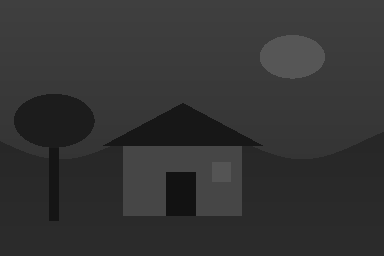

**Adjusted image — CPU reference preview:**

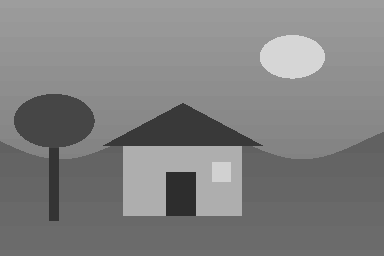

These previews are calculated on the CPU. Later cells display and check the actual GPU output. Rounding and clipping at 255 mean the final average may differ from the target. Multiplying a completely black image cannot recover any detail.

### How shared memory helps

Each thread reads one pixel, then stores its brightness in the block's shared array. Threads add pairs of values until just one block total remains. The number of active additions halves each round; **all threads still reach every barrier**.

This example uses 16 values to make the steps readable. The CUDA program defaults to 256 threads per block.



For the first round, thread 0 adds slots 0 and 8, thread 1 adds slots 1 and 9, and so on. A barrier separates rounds so the next additions read completed results. Threads beyond the final image pixel contribute zero and still participate in the barriers.

Each block has its own shared array. The CPU adds the block totals and computes `gain = target / mean`; a second kernel applies that gain. This exercise demonstrates cooperation and correctness, rather than claiming a speedup over another implementation.

### 1. Choose the image and launch settings

Change these variables and rerun all subsequent cells. `darkness` controls the starting image; smaller values make it darker. `target_brightness` is the desired average. `threads_per_block` must be a power of two, such as 64, 128, or 256.

To try your own image, replace `input_pixels` with a grayscale byte buffer containing exactly `width * height` pixel values.

In [ ]:
from pathlib import Path
from IPython.display import Image, SVG, display
import json
import math
import runpy

width = 384
height = 256
darkness = 0.35
target_brightness = 128
threads_per_block = 256

assert type(width) is int and type(height) is int
assert 1 <= width <= 4096 and 1 <= height <= 4096
assert type(target_brightness) is int and 1 <= target_brightness <= 255
assert type(threads_per_block) is int and 1 <= threads_per_block <= 1024
assert threads_per_block & (threads_per_block - 1) == 0

image_tools = runpy.run_path("exercises/06-shared-memory/image_tools.py")
output_dir = Path("image_brightness_output")
output_dir.mkdir(exist_ok=True)
input_pixels = image_tools["make_scene"](width, height, darkness)
(output_dir / "input.raw").write_bytes(input_pixels)
image_tools["write_png"](output_dir / "input.png", input_pixels, width, height)
print(f"Original average brightness: {sum(input_pixels) / len(input_pixels):.3f}")
display(Image(filename=str(output_dir / "input.png")))

### 2. Inspect and compile the CUDA program

Find the `shared[]` array, the reduction loop, and the barriers. Notice that shared memory holds temporary sums; the pixel adjustment kernel simply uses the computed gain.

In [ ]:
!cat exercises/06-shared-memory/brightness.cu

In [ ]:
!nvcc -O2 exercises/06-shared-memory/brightness.cu -o image_brightness_output/brightness

### 3. Run the GPU computation

The executable saves adjusted pixels, measured statistics, and one partial sum per block. This also works when the image size is not an exact multiple of the block size.

In [ ]:
# Remove previous results so a failed run cannot display stale GPU data.
for name in ["adjusted.raw", "stats.json", "block_sums.txt", "adjusted_gpu.png"]:
    (output_dir / name).unlink(missing_ok=True)

!./image_brightness_output/brightness image_brightness_output/input.raw {width} {height} {target_brightness} {threads_per_block} image_brightness_output/adjusted.raw image_brightness_output/stats.json image_brightness_output/block_sums.txt

### 4. Check the GPU results and display the adjusted image

Check every block sum and every output pixel against the CPU reference. All comparisons should pass before interpreting the image.

In [ ]:
gpu_pixels = (output_dir / "adjusted.raw").read_bytes()
stats = json.loads((output_dir / "stats.json").read_text())
block_sums = [int(line) for line in (output_dir / "block_sums.txt").read_text().splitlines()]
reference_pixels, reference_mean, reference_gain = image_tools["adjust"](input_pixels, target_brightness)
expected_sums = [sum(input_pixels[i:i + threads_per_block])
                 for i in range(0, len(input_pixels), threads_per_block)]

assert stats["threads"] == threads_per_block
assert stats["blocks"] == len(expected_sums)
assert block_sums == expected_sums, "A GPU block sum differs from the CPU sum"
assert stats["sum"] == sum(input_pixels)
assert math.isclose(stats["mean"], reference_mean, rel_tol=1e-12, abs_tol=1e-12)
assert math.isclose(stats["gain"], reference_gain, rel_tol=1e-12, abs_tol=1e-12)
assert gpu_pixels == reference_pixels, "GPU-adjusted pixels differ from the CPU reference"

image_tools["write_png"](output_dir / "adjusted_gpu.png", gpu_pixels, width, height)
print("PASSED: every block sum and output pixel matches the CPU reference.")
print(f"Original mean: {stats['mean']:.3f}; gain: {stats['gain']:.3f}")
print(f"Adjusted mean: {sum(gpu_pixels) / len(gpu_pixels):.3f}; target: {target_brightness}")
print("Original:")
display(Image(filename=str(output_dir / "input.png")))
print("GPU-adjusted:")
display(Image(filename=str(output_dir / "adjusted_gpu.png")))

### 5. Inspect the reduction on a small sample

The following diagram uses 16 pixels sampled across your generated image. It illustrates one small block's reduction; it is calculated from notebook variables, rather than tracing intermediate GPU instructions.

In [ ]:
sample_pixels = [input_pixels[i * (len(input_pixels) - 1) // 15] for i in range(16)]
display(SVG(data=image_tools["reduction_svg"](sample_pixels)))
print(f"Sample sum: {sum(sample_pixels)}; sample mean: {sum(sample_pixels) / 16:.3f}")

### Experiment

1. Set `darkness = 0.2`, rerun from step 1, and inspect the original and adjusted images. How does the gain change?
2. Try targets of 80, 128, and 180. When do bright areas lose detail because their values clip at 255?
3. Try 64, 128, and 256 threads per block. How many block sums are produced? Do the adjusted pixels change?
4. Use `width = 383` and `height = 251` to create an incomplete final block. Why must unused threads write zero and still reach the barriers?
5. Why do we combine block sums separately instead of reading another block's shared array?

### Observations

Record the starting mean, target, gain, number of blocks, and what changed in the image.